# ST5227 Applied Statistical Learning Course Project
Group 10: Gu Yunkai, Huang Xunheng, Lai Xining, Sun Haoxuan

In [36]:
# Install required Python libraries

%pip install numpy pandas matplotlib seaborn scipy scikit-learn pygam

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Note: you may need to restart the kernel to use updated packages.


## Research Question: How accurately can statistical learning models predict hotel booking cancellations, which factors are most influential in determining cancellation probability, and what is the trade-off between predictive performance and model interpretability?

**Dataset:** Hotel Booking Demand Dataset

**Task:** Binary Classification

---

## 1. Introduction

### 1.1 Background and Motivation

Traveling has become an important part of modern life, offering precious opportunities for relaxation, exploration, and new experiences. Whether you are traveling for leisure or for business, accomodation remains an essential component of the journey, and hotel reservations are often made well in advance. However, travel plans do not always go as expected. The changes in personal schedules, unexpected circumstances, or simply the substitution effect of better accommodation options may lead travelers to cancel their reservations.

From the perspective of hotel operators, booking cancellations introduce uncertainty into occupancy planning and revenue management. Frequent or unexpected cancellations may result in unoccupied rooms, lost revenue opportunities, and difficulties in allocating resources efficiently. Therefore, understanding the factors associated with cancellations and predicting their likelihood can help hotels make more informed operational decisions.

With the availability of detailed hotel booking data, statistical learning methods provide an opportunity to investigate cancellation behavior and identify meaningful patterns among booking characteristics. In this project, we analyze the **Hotel Booking Demand Dataset** and apply various statistical learning techniques to predict whether a reservation will be canceled.

Beyond achieving high predictive accuracy, we are also interested in understanding the underlying relationships between booking characteristics and cancellation behavior. In particular, we aim to investigate whether nonlinear models offer meaningful improvements over simpler models, identify the most influential predictors, and evaluate the trade-off between predictive performance and model interpretability.

**Our central research question is:**

*How accurately can statistical learning models predict hotel booking cancellations, which booking characteristics are most strongly associated with cancellation probability, and what is the trade-off between predictive performance and model interpretability?*

### 1.2 Research Objectives

The primary objective of this project is to develop and compare statistical learning models for predicting hotel booking cancellations. Beyond predictive accuracy, we aim to understand the underlying relationships between booking characteristics and cancellation behavior.

Specifically, we seek to investigate whether nonlinear models outperform simpler linear models, identify the most influential predictors, and evaluate the trade-off between model interpretability and predictive performance. Additionally, we will apply unsupervised learning techniques to explore potential patterns and structures within the dataset.

Ultimately, our goal is to identify a reliable and interpretable approach to predicting cancellations while providing meaningful insights for hotel management.

### 1.3 Research Questions

1. **Model Performance:** Which statistical learning model achieves the best predictive performance in identifying hotel booking cancellations?
2. **Linearity vs. Nonlinearity:** Do nonlinear models significantly outperform linear models in predicting cancellations?
3. **Feature Importance:** Which booking characteristics are most influential in predicting cancellation probability?
4. **Interpretability vs. Accuracy:** What is the trade-off between predictive performance and model interpretability?
5. **Unsupervised Learning:** Can dimensionality reduction or clustering reveal meaningful patterns in hotel booking behavior?

In [3]:
data = pd.read_csv("/Users/marksunhaoxuan/Downloads/hotel_bookings.csv")

print(data.shape)
print(data.dtypes.value_counts())

display(data.head())
display(data.describe(include="all").T)

print(data["is_canceled"].value_counts())
print(data["is_canceled"].value_counts(normalize=True))

(119390, 32)
int64      16
str        12
float64     4
Name: count, dtype: int64


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,City Hotel,1,35,2016,March,13,25,0,1,2,...,Non Refund,12.0,NaN,0,Transient,5400.0,0,0,Canceled,2016/2/19
1,City Hotel,0,0,2017,May,19,9,0,1,1,...,No Deposit,159.0,NaN,0,Transient,510.0,0,0,Check-Out,2017/5/10
2,Resort Hotel,0,1,2015,July,29,15,0,1,2,...,No Deposit,NaN,NaN,0,Transient,508.0,1,0,Check-Out,2015/7/16
3,City Hotel,0,81,2016,December,53,31,1,1,2,...,No Deposit,NaN,NaN,0,Transient-Party,451.5,0,4,Check-Out,2017/1/2
4,Resort Hotel,1,378,2017,August,31,1,4,10,2,...,No Deposit,314.0,NaN,0,Transient,450.0,0,0,Canceled,2016/7/22


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
hotel,119390,2,City Hotel,79330,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_canceled,119390.0,NaN,NaN,NaN,0.370416,0.482918,0.0,0.0,0.0,1.0,1.0
lead_time,119390.0,NaN,NaN,NaN,104.011416,106.863097,0.0,18.0,69.0,160.0,737.0
arrival_date_year,119390.0,NaN,NaN,NaN,2016.156554,0.707476,2015.0,2016.0,2016.0,2017.0,2017.0
arrival_date_month,119390,12,August,13877,NaN,NaN,NaN,NaN,NaN,NaN,NaN
arrival_date_week_number,119390.0,NaN,NaN,NaN,27.165173,13.605138,1.0,16.0,28.0,38.0,53.0
arrival_date_day_of_month,119390.0,NaN,NaN,NaN,15.798241,8.780829,1.0,8.0,16.0,23.0,31.0
stays_in_weekend_nights,119390.0,NaN,NaN,NaN,0.927599,0.998613,0.0,0.0,1.0,2.0,19.0
stays_in_week_nights,119390.0,NaN,NaN,NaN,2.500302,1.908286,0.0,1.0,2.0,3.0,50.0
adults,119390.0,NaN,NaN,NaN,1.856403,0.579261,0.0,2.0,2.0,2.0,55.0


is_canceled
0    75166
1    44224
Name: count, dtype: int64
is_canceled
0    0.629584
1    0.370416
Name: proportion, dtype: float64


## 2. Dataset Description and Initial Exploration

### 2.1 Dataset Overview

This project uses the *Hotel Booking Demand Dataset*, which contains information on hotel reservations, including booking characteristics, customer information, and cancellation outcomes. The dataset consists of 119,390 observations and 32 variables, covering both City Hotels and Resort Hotels.

Our target variable is `is_canceled`, a binary indicator of whether a reservation was canceled (1) or not canceled (0). The remaining variables provide potential predictors, including booking lead time, average daily rate, deposit type, and previous cancellation history.

Before applying statistical learning methods, we first examine the dataset's structure, variable types, missing values, and summary statistics to identify potential data quality issues and determine appropriate preprocessing steps.

In [13]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# Display first five observations
data.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,City Hotel,1,35,2016,March,13,25,0,1,2,...,Non Refund,12.0,NaN,0,Transient,5400.0,0,0,Canceled,2016/2/19
1,City Hotel,0,0,2017,May,19,9,0,1,1,...,No Deposit,159.0,NaN,0,Transient,510.0,0,0,Check-Out,2017/5/10
2,Resort Hotel,0,1,2015,July,29,15,0,1,2,...,No Deposit,NaN,NaN,0,Transient,508.0,1,0,Check-Out,2015/7/16
3,City Hotel,0,81,2016,December,53,31,1,1,2,...,No Deposit,NaN,NaN,0,Transient-Party,451.5,0,4,Check-Out,2017/1/2
4,Resort Hotel,1,378,2017,August,31,1,4,10,2,...,No Deposit,314.0,NaN,0,Transient,450.0,0,0,Canceled,2016/7/22


### 2.2 Dataset Structure

We first examine the dimensions, data types, and general structure of the dataset to understand the available observations and variables.

In [14]:
# Examine the dimensions and structure of the dataset
print("Dataset dimensions:", data.shape)
data.info()

Dataset dimensions: (119390, 32)
<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  

### 2.3 Variable Types and Target Variable

The dataset contains both numerical and categorical variables. Identifying these variable types is important because different statistical learning methods may require different preprocessing techniques.

We also examine the distribution of the target variable, `is_canceled`, to understand the proportion of canceled and non-canceled reservations.

In [22]:
# Identify numerical and categorical variables
numerical_cols = data.select_dtypes(
    include=np.number
).columns.tolist()

categorical_cols = data.select_dtypes(
    include=["str", "object", "category"]
).columns.tolist()

print("Numerical variables:")
print(numerical_cols)

print("\nCategorical variables:")
print(categorical_cols)

Numerical variables:
['is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'agent', 'company', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']

Categorical variables:
['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type', 'reservation_status', 'reservation_status_date']


Cancellation counts:
is_canceled
0    75166
1    44224
Name: count, dtype: int64

Cancellation proportions:
is_canceled
0    0.629584
1    0.370416
Name: proportion, dtype: float64


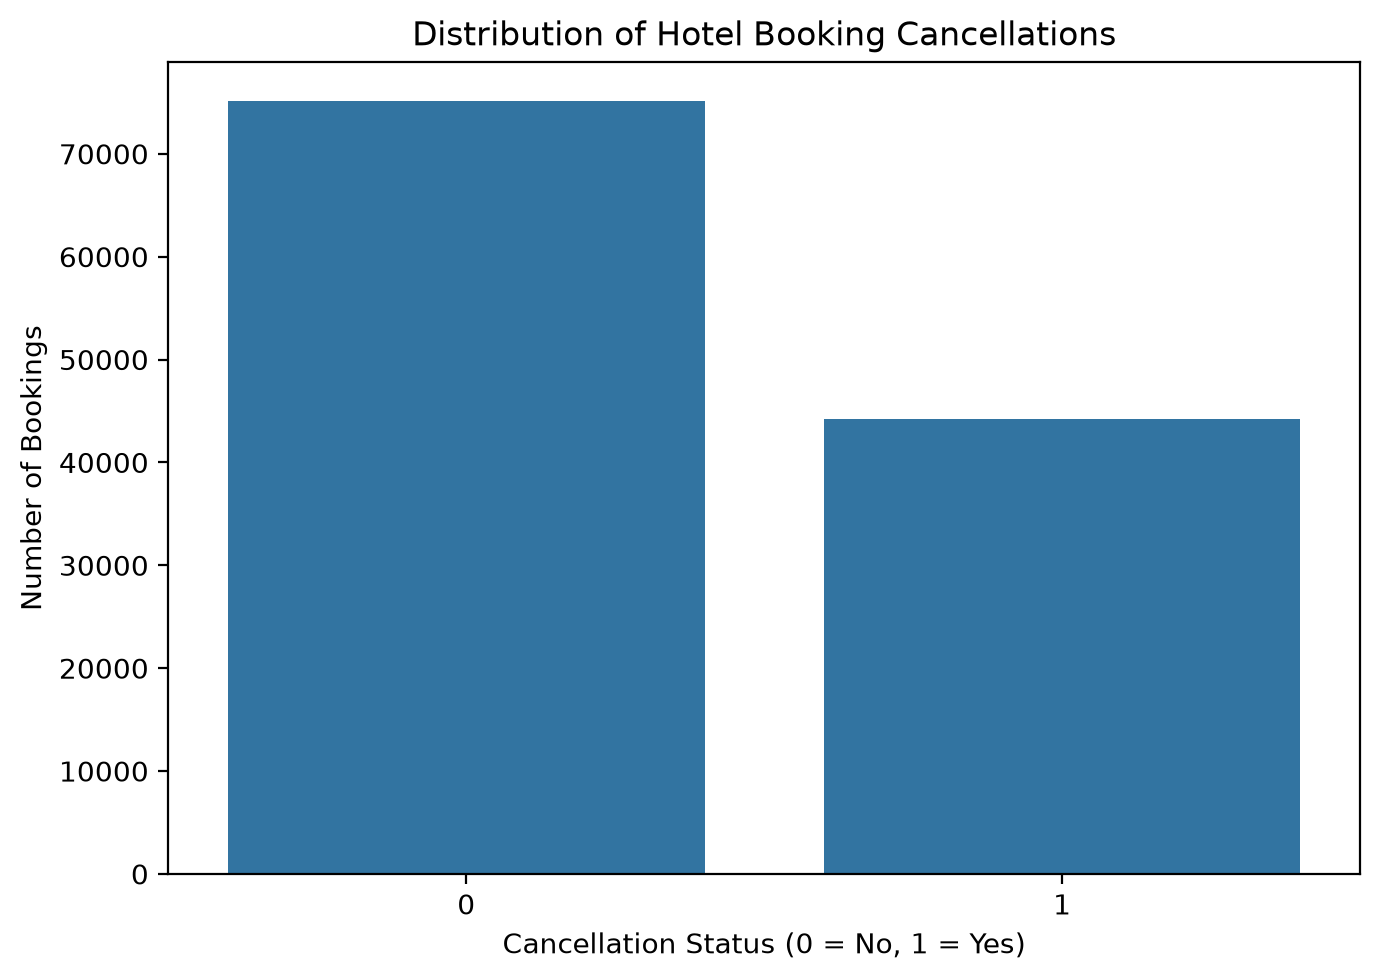

In [16]:
# Target variable counts
print("Cancellation counts:")
print(data["is_canceled"].value_counts())

# Target variable proportions
print("\nCancellation proportions:")
print(data["is_canceled"].value_counts(normalize=True))

# Visualize cancellation distribution
plt.figure(figsize=(7, 5))

sns.countplot(
    data=data,
    x="is_canceled"
)

plt.title("Distribution of Hotel Booking Cancellations")
plt.xlabel("Cancellation Status (0 = No, 1 = Yes)")
plt.ylabel("Number of Bookings")

plt.tight_layout()
plt.show()

### 2.4 Missing Values and Duplicate Records

Missing values and duplicate observations may affect model estimation and predictive performance. We examine the extent of missing data across variables and identify duplicate records before deciding on appropriate preprocessing methods.

In [17]:
# Calculate missing values
missing = pd.DataFrame({
    "Missing Count": data.isnull().sum(),
    "Missing Percentage": data.isnull().mean() * 100
})

# Display variables containing missing values
missing = missing[
    missing["Missing Count"] > 0
].sort_values(
    "Missing Count", ascending=False
)

display(missing)

,Missing Count,Missing Percentage
company,112593,94.306893
agent,16340,13.686238
country,488,0.408744
children,4,0.003350


In [18]:
# Identify duplicate observations
duplicate_count = data.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

print(
    "Percentage of duplicate rows:",
    round(duplicate_count / len(data) * 100, 2),
    "%"
)

Number of duplicate rows: 31994
Percentage of duplicate rows: 26.8 %


### 2.5 Summary Statistics

We examine descriptive statistics for numerical and categorical variables to better understand their distributions, ranges, and potential irregularities.

For numerical variables, we consider measures such as the mean, standard deviation, and quartiles. For categorical variables, we examine the number of unique categories and the most frequently occurring values.

In [20]:
# Summary statistics for numerical variables
data.describe().T

,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.370416,0.482918,0.00,0.00,0.000,1.0,1.0
lead_time,119390.0,104.011416,106.863097,0.00,18.00,69.000,160.0,737.0
arrival_date_year,119390.0,2016.156554,0.707476,2015.00,2016.00,2016.000,2017.0,2017.0
arrival_date_week_number,119390.0,27.165173,13.605138,1.00,16.00,28.000,38.0,53.0
arrival_date_day_of_month,119390.0,15.798241,8.780829,1.00,8.00,16.000,23.0,31.0
stays_in_weekend_nights,119390.0,0.927599,0.998613,0.00,0.00,1.000,2.0,19.0
stays_in_week_nights,119390.0,2.500302,1.908286,0.00,1.00,2.000,3.0,50.0
adults,119390.0,1.856403,0.579261,0.00,2.00,2.000,2.0,55.0
children,119386.0,0.103890,0.398561,0.00,0.00,0.000,0.0,10.0
babies,119390.0,0.007949,0.097436,0.00,0.00,0.000,0.0,10.0


In [23]:
# Summary statistics for categorical variables
data.describe(include=["str", "object", "category"]).T

,count,unique,top,freq
hotel,119390,2,City Hotel,79330
arrival_date_month,119390,12,August,13877
meal,119390,5,BB,92310
country,118902,177,PRT,48590
market_segment,119390,8,Online TA,56477
distribution_channel,119390,5,TA/TO,97870
reserved_room_type,119390,10,A,85994
assigned_room_type,119390,12,A,74053
deposit_type,119390,3,No Deposit,104641
customer_type,119390,4,Transient,89613


### 2.6 Initial Observations

The dataset contains 119,390 observations and 32 variables, including both numerical and categorical features. Approximately 37.04% of bookings were canceled, indicating a moderate class imbalance. City Hotels account for the majority of reservations (66.45%).

The average booking lead time is approximately 104 days, with a maximum of 737 days, suggesting substantial variation in how far in advance reservations are made. Additionally, several numerical variables contain potentially unusual values that warrant further investigation.

Missing values are concentrated in company (94.31%) and agent (13.69%), while 26.8% of observations are exact duplicates. Since identical records do not necessarily represent the same reservation, further investigation is required before deciding whether to remove them.

Finally, variables such as reservation_status and reservation_status_date contain information about reservation outcomes and must be excluded from predictive modeling to prevent data leakage. These findings will guide our subsequent exploratory analysis and preprocessing decisions.

## 3. Exploratory Data Analysis (EDA)

### 3.1 Cancellation Rates by Hotel Type

We begin by examining whether cancellation behavior differs between City Hotels and Resort Hotels. By comparing cancellation rates across hotel types, we aim to identify potential differences in booking patterns that may be relevant for subsequent predictive modeling.

,Total_Bookings,Cancellations,Cancellation_Rate
hotel,,,
City Hotel,79330,33102,41.73
Resort Hotel,40060,11122,27.76


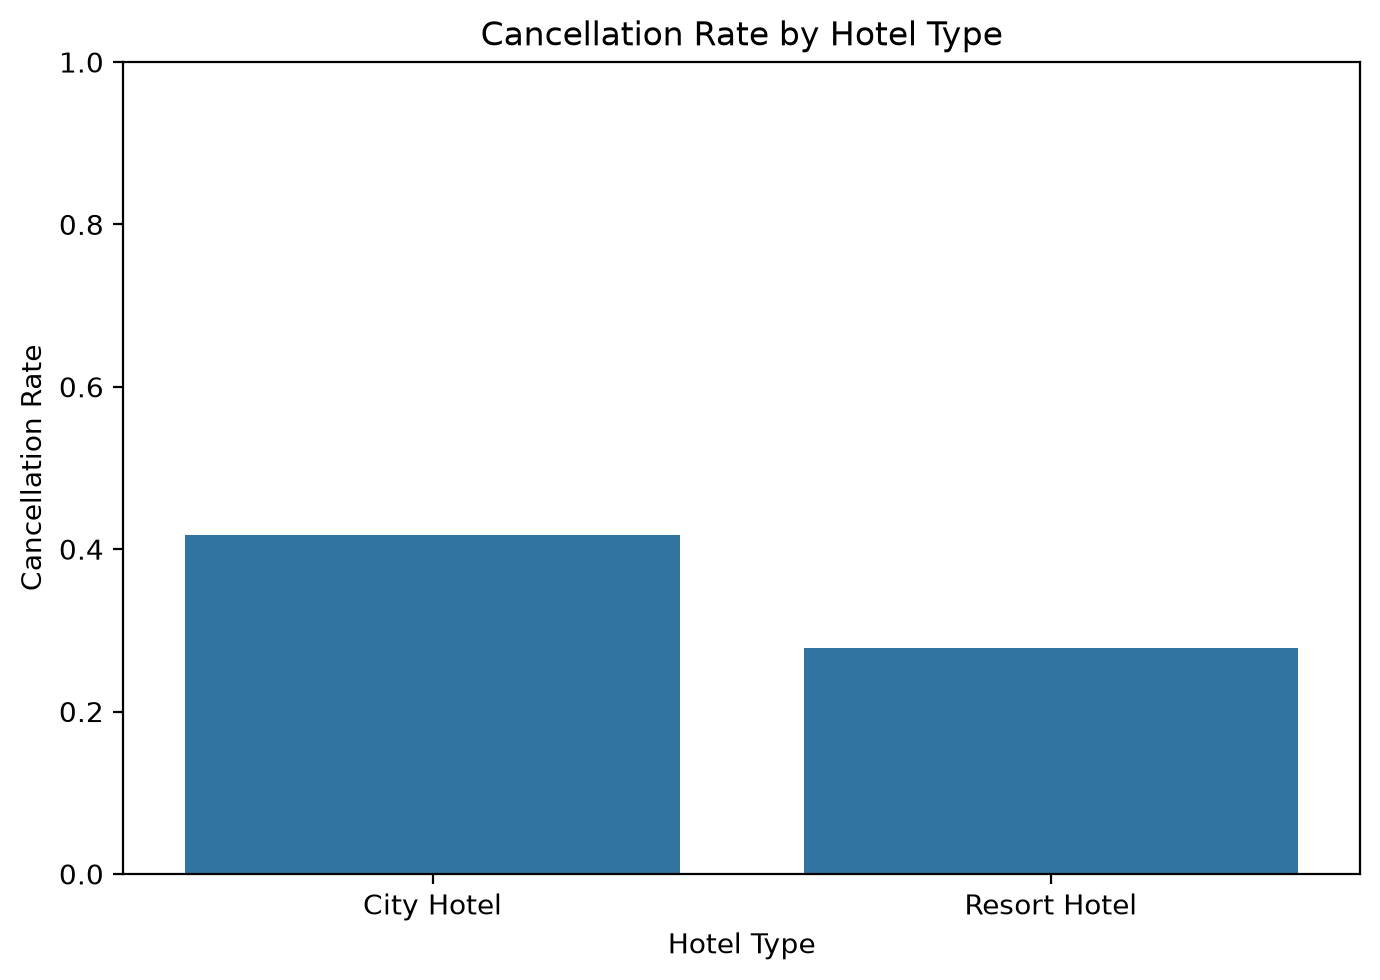

In [24]:
# Calculate cancellation rates by hotel type
hotel_summary = data.groupby("hotel")["is_canceled"].agg(
    Total_Bookings="count",
    Cancellations="sum",
    Cancellation_Rate="mean"
)

hotel_summary["Cancellation_Rate"] *= 100

display(hotel_summary.round(2))

# Visualize cancellation rates by hotel type
plt.figure(figsize=(7, 5))

sns.barplot(
    data=data,
    x="hotel",
    y="is_canceled",
    errorbar=None
)

plt.title("Cancellation Rate by Hotel Type")
plt.xlabel("Hotel Type")
plt.ylabel("Cancellation Rate")
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

City Hotels have a substantially higher cancellation rate (41.73%) than Resort Hotels (27.76%), representing a difference of approximately 14 percentage points. This suggests that hotel type is associated with cancellation behavior and may be a useful predictor in our classification models.

However, this difference may also reflect other booking characteristics, such as lead time, customer type, or deposit policies. Further analysis is needed to determine whether hotel type remains influential after accounting for these factors.

### 3.2 Lead Time and Cancellation Probability

Booking lead time may influence cancellation behavior, as reservations made further in advance allow more time for travel plans to change. We examine the relationship between lead time and cancellation probability to identify potential trends and nonlinear patterns that may be relevant for model selection.

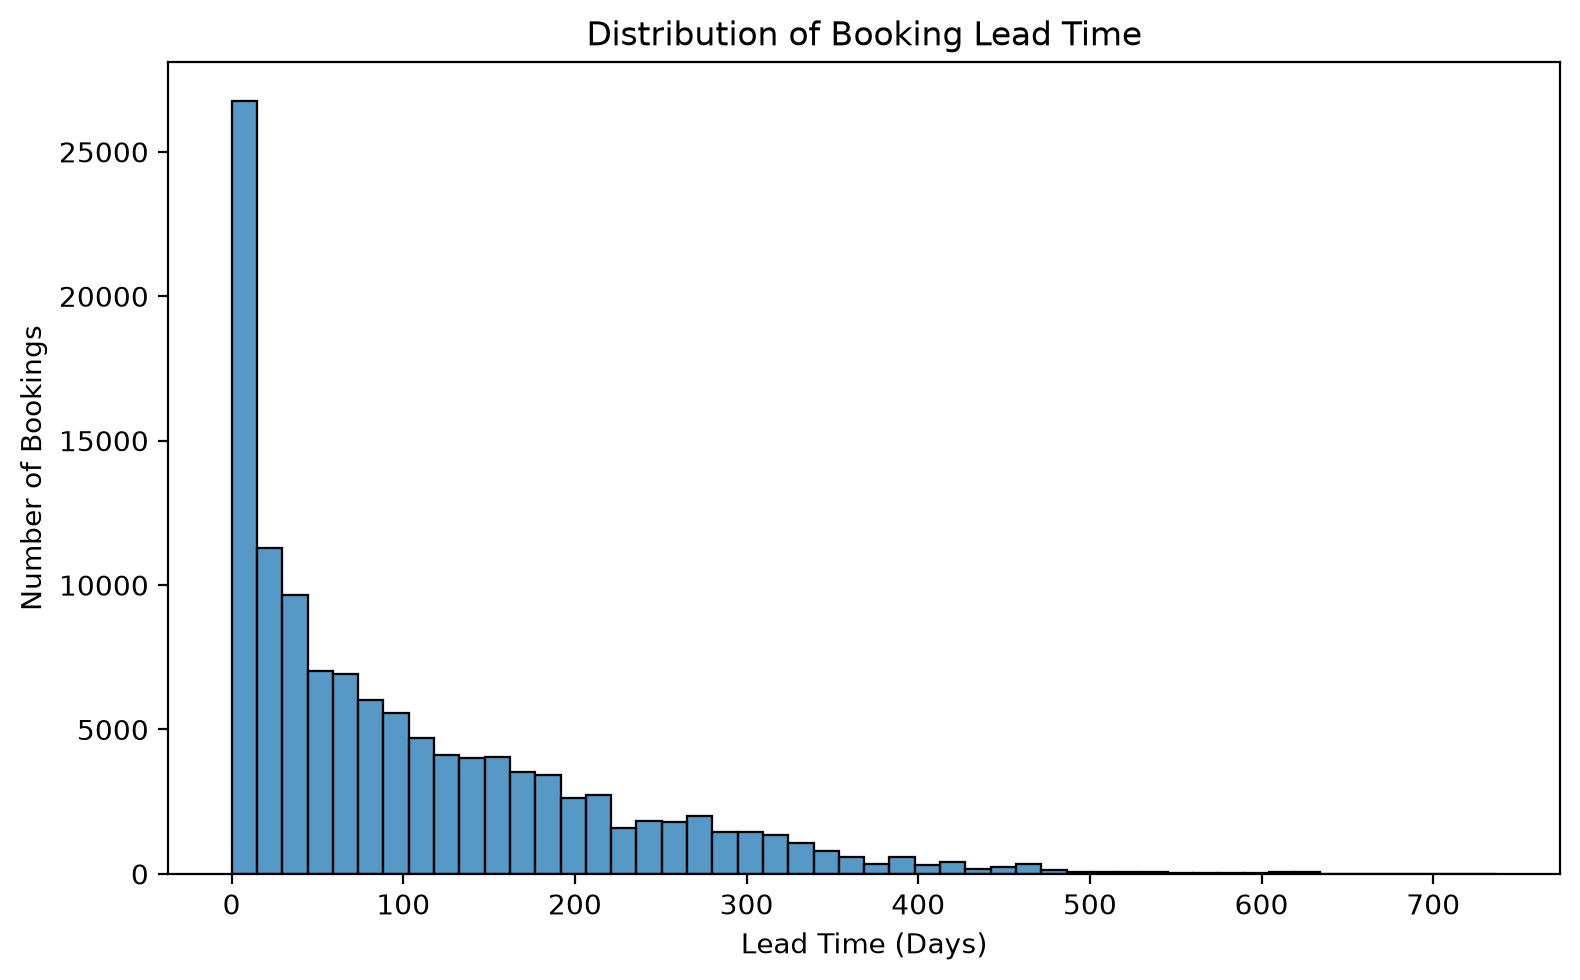

,Total_Bookings,Cancellation_Rate
lead_time_group,,
0-30,38706,18.56
31-60,16970,36.38
61-90,12583,39.47
91-120,10434,44.52
121-180,16005,44.84
181-270,13380,48.27
271-365,8164,67.23
365+,3148,67.66


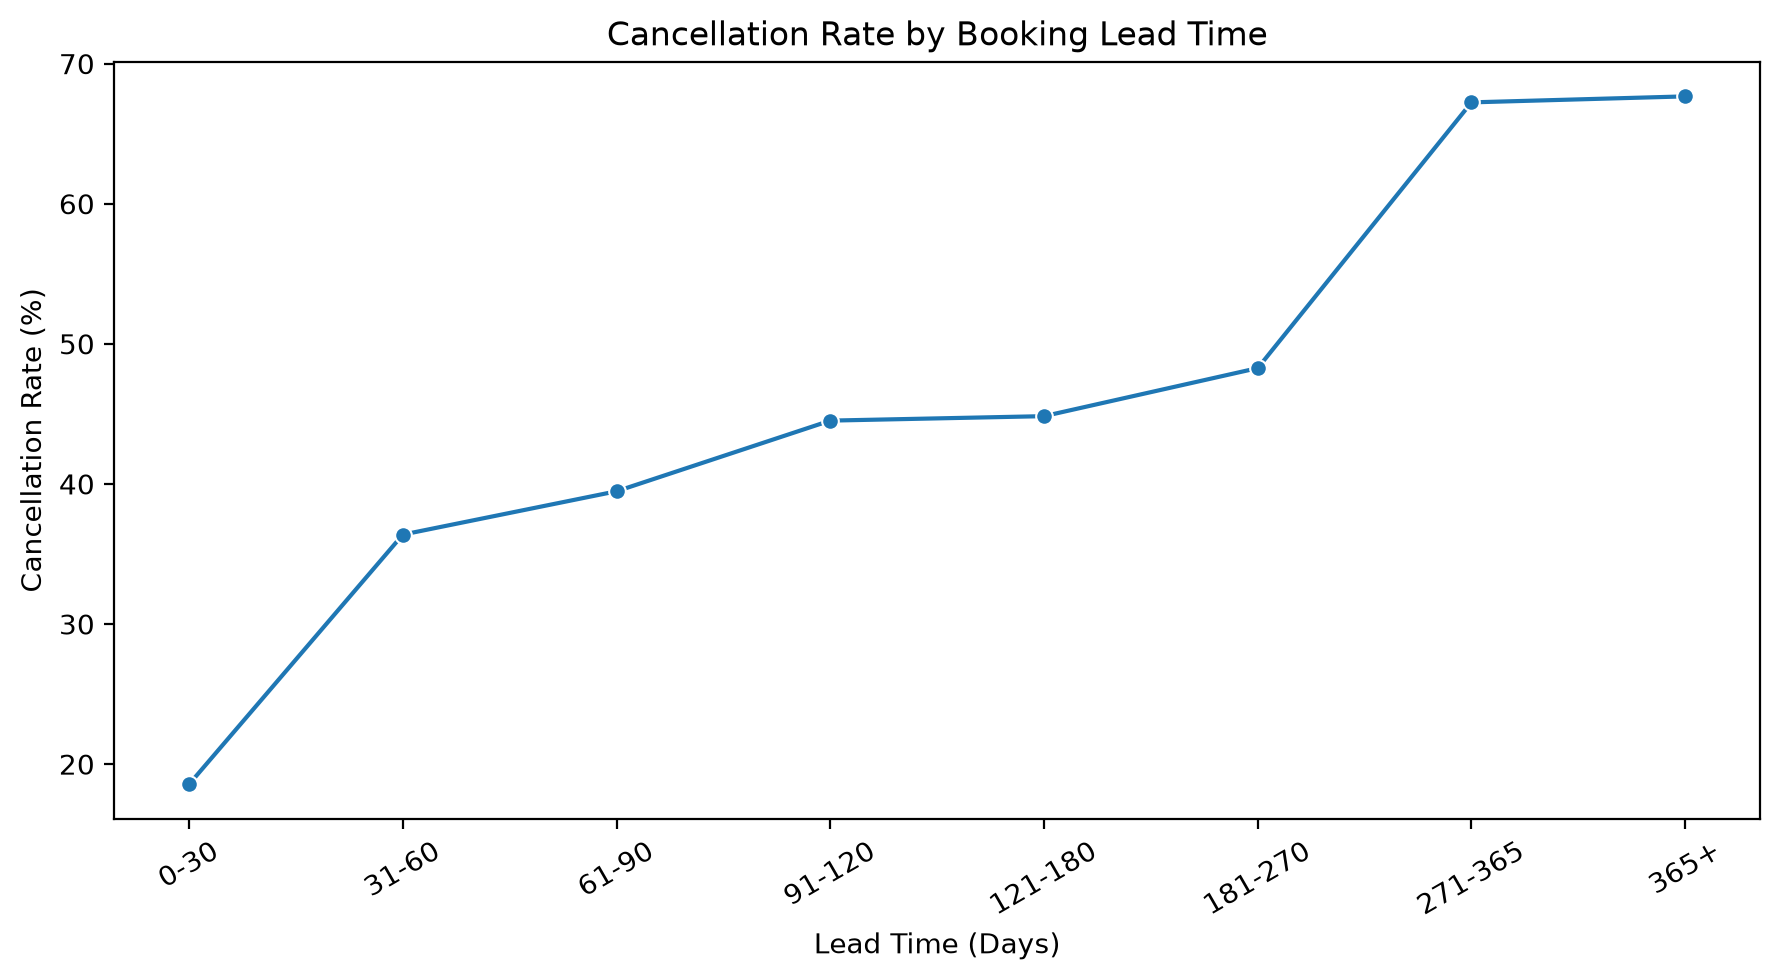

In [25]:
# Distribution of booking lead time
plt.figure(figsize=(8, 5))

sns.histplot(
    data=data,
    x="lead_time",
    bins=50
)

plt.title("Distribution of Booking Lead Time")
plt.xlabel("Lead Time (Days)")
plt.ylabel("Number of Bookings")
plt.tight_layout()
plt.show()


# Group lead time into intervals
bins = [0, 30, 60, 90, 120, 180, 270, 365, np.inf]

labels = [
    "0-30", "31-60", "61-90", "91-120",
    "121-180", "181-270", "271-365", "365+"
]

data["lead_time_group"] = pd.cut(
    data["lead_time"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# Calculate cancellation rates by lead-time group
lead_time_summary = data.groupby(
    "lead_time_group",
    observed=True
)["is_canceled"].agg(
    Total_Bookings="count",
    Cancellation_Rate="mean"
)

lead_time_summary["Cancellation_Rate"] *= 100

display(lead_time_summary.round(2))


# Plot cancellation rates across lead-time groups
plt.figure(figsize=(9, 5))

sns.lineplot(
    data=lead_time_summary.reset_index(),
    x="lead_time_group",
    y="Cancellation_Rate",
    marker="o"
)

plt.title("Cancellation Rate by Booking Lead Time")
plt.xlabel("Lead Time (Days)")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Booking lead time shows a strong positive association with cancellation probability. Reservations made within 30 days of arrival have a cancellation rate of only 18.56%, compared with approximately 67% for reservations made more than 270 days in advance.

The relationship appears nonlinear, with particularly sharp increases at shorter lead times and beyond 270 days. This suggests that flexible models, such as GAMs and tree-based methods, may capture cancellation patterns more effectively than models assuming a linear effect of lead time on the log-odds of cancellation.

However, these are unadjusted associations, and further modeling is required to determine whether the observed relationship persists after accounting for other booking characteristics.

### 3.3 Average Daily Rate (ADR) and Cancellation Probability

Room pricing may be associated with booking cancellation behavior, as customers booking more expensive accommodation may have different cancellation tendencies. We examine the distribution of average daily rates (ADR) and investigate whether cancellation rates vary across different price levels.

ADR Summary Statistics:


count    119390.000000
mean        101.831122
std          50.535790
min          -6.380000
25%          69.290000
50%          94.575000
75%         126.000000
max        5400.000000
Name: adr, dtype: float64


Number of negative ADR values: 1
Number of zero ADR values: 1959


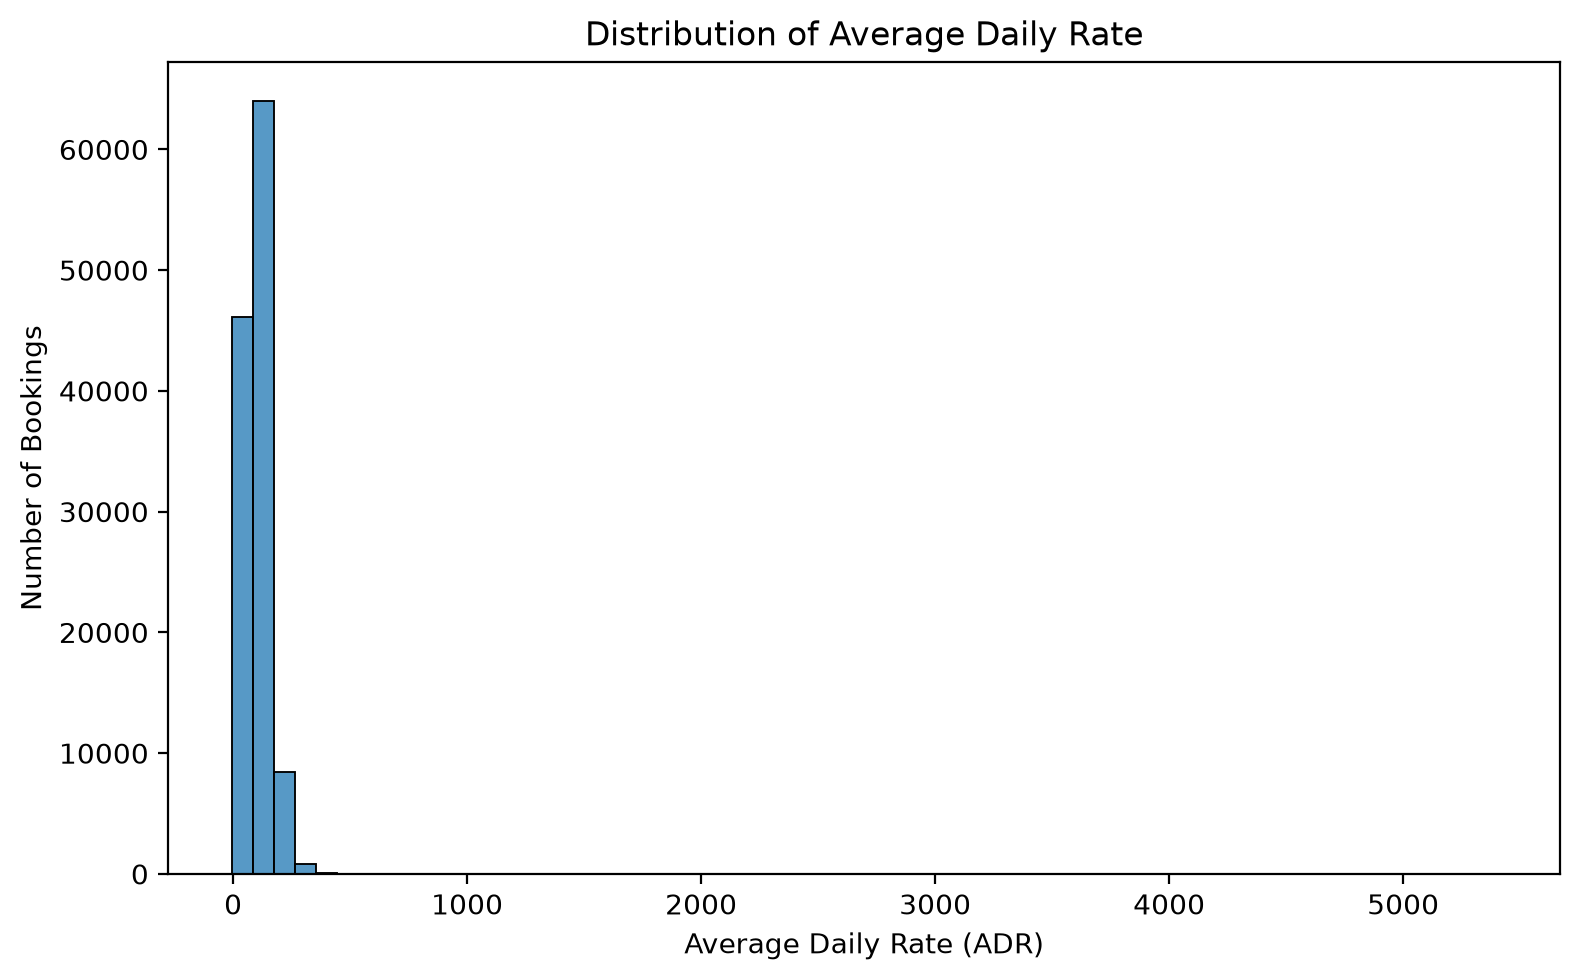

In [26]:
# Examine ADR distribution
print("ADR Summary Statistics:")
display(data["adr"].describe())

print("\nNumber of negative ADR values:",
      (data["adr"] < 0).sum())

print("Number of zero ADR values:",
      (data["adr"] == 0).sum())

# Display ADR distribution
plt.figure(figsize=(8, 5))

sns.histplot(data=data, x="adr", bins=60)

plt.title("Distribution of Average Daily Rate")
plt.xlabel("Average Daily Rate (ADR)")
plt.ylabel("Number of Bookings")

plt.tight_layout()
plt.show()

The ADR distribution exhibits substantial variation, with a median of 94.58 and a maximum of 5,400, suggesting the presence of extreme observations. Additionally, one negative ADR value and 1,959 zero-ADR values were identified.

These observations warrant further investigation before modeling. To prevent extreme values from distorting our exploratory visualizations, we will examine cancellation patterns across ADR intervals while retaining the original dataset unchanged.

Cancellation rates for unusual ADR values:


,Total_Bookings,Cancellation_Rate
ADR_Category,,
Negative ADR,1,0.00
Positive ADR,117430,37.48
Zero ADR,1959,10.87


,Total_Bookings,Cancellation_Rate
ADR_Group,,
"(0.259, 65.0]",24668,36.34
"(65.0, 85.67]",22470,34.34
"(85.67, 106.0]",23331,39.64
"(106.0, 135.0]",23627,39.35
"(135.0, 5400.0]",23334,37.65


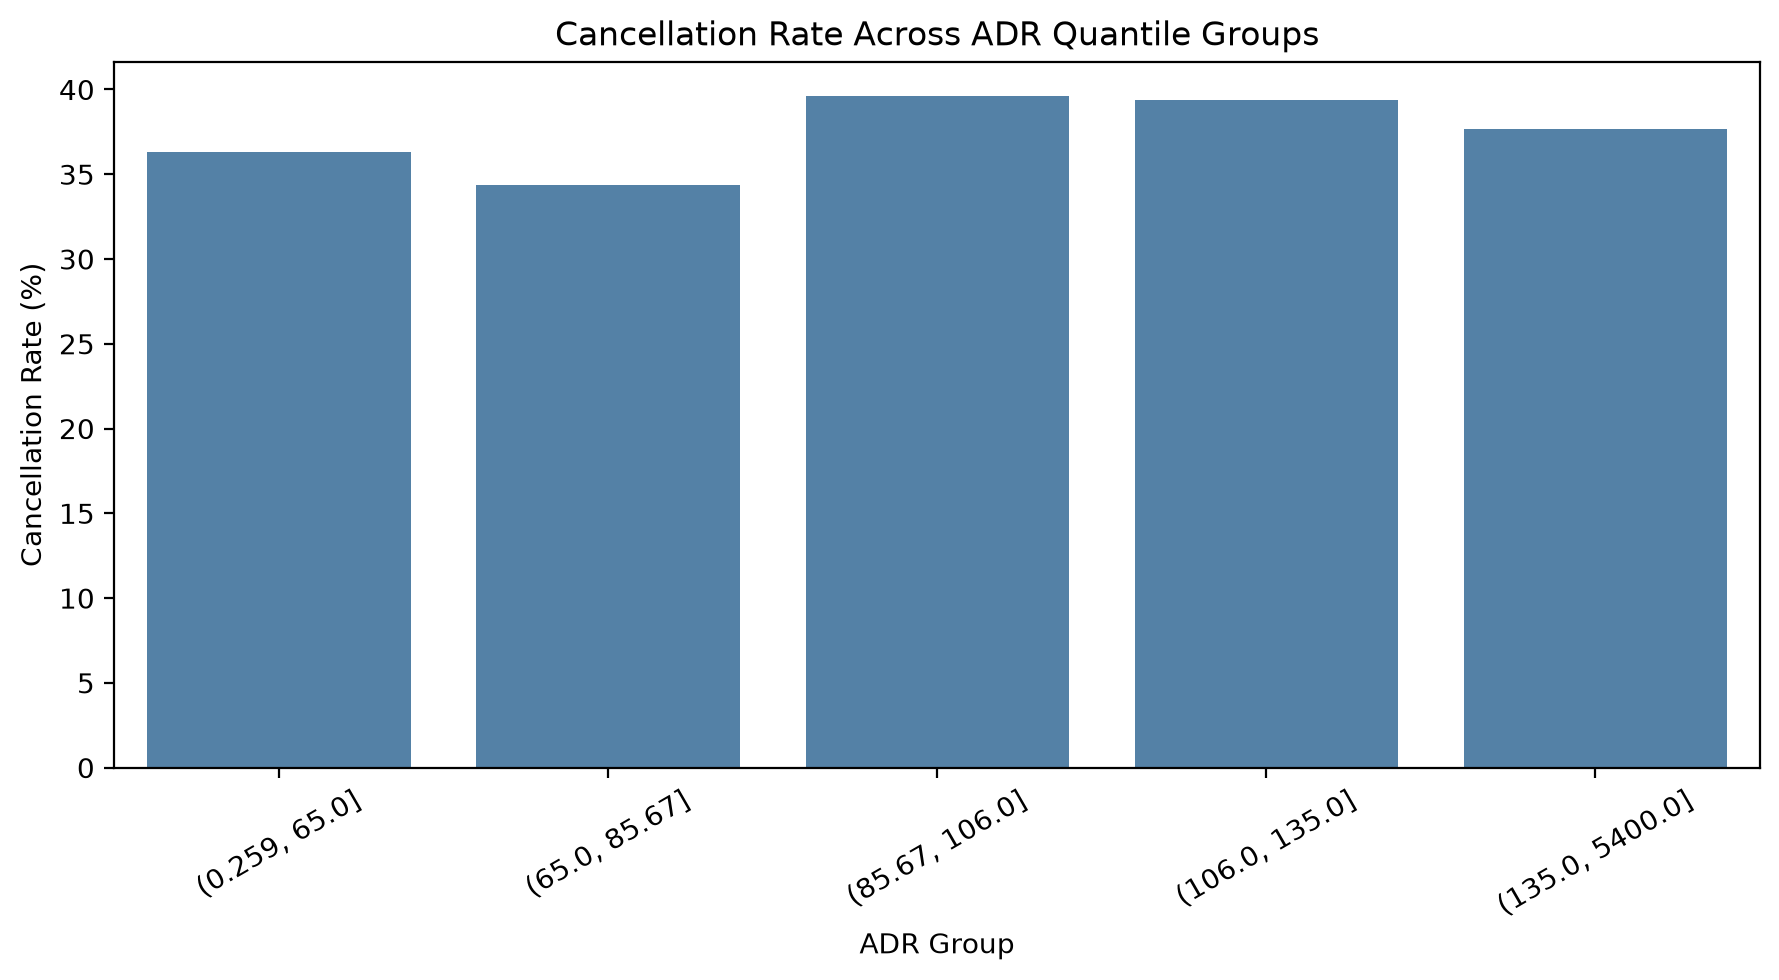

In [34]:
# Examine cancellation rate for zero and negative ADR
print("Cancellation rates for unusual ADR values:")

display(
    data.assign(
        ADR_Category=np.select(
            [
                data["adr"] < 0,
                data["adr"] == 0
            ],
            [
                "Negative ADR",
                "Zero ADR"
            ],
            default="Positive ADR"
        )
    ).groupby("ADR_Category")["is_canceled"].agg(
        Total_Bookings="count",
        Cancellation_Rate="mean"
    ).assign(
        Cancellation_Rate=lambda x: x["Cancellation_Rate"] * 100
    ).round(2)
)


# Divide positive ADR observations into five quantile groups
positive_adr = data.loc[data["adr"] > 0].copy()

positive_adr["ADR_Group"] = pd.qcut(
    positive_adr["adr"],
    q=5,
    duplicates="drop"
)

# Calculate cancellation rates
adr_summary = positive_adr.groupby(
    "ADR_Group",
    observed=True
)["is_canceled"].agg(
    Total_Bookings="count",
    Cancellation_Rate="mean"
)

adr_summary["Cancellation_Rate"] *= 100

display(adr_summary.round(2))


# Visualize cancellation rates across ADR groups
plt.figure(figsize=(9, 5))

sns.barplot(
    x=[str(x) for x in adr_summary.index],
    y=adr_summary["Cancellation_Rate"],
    color="steelblue"
)

plt.title("Cancellation Rate Across ADR Quantile Groups")
plt.xlabel("ADR Group")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

ADR does not exhibit a clear monotonic relationship with cancellation probability. Across the five positive-ADR quantile groups, cancellation rates fluctuate between 34.34% and 39.64%, suggesting that higher room prices are not consistently associated with higher cancellation rates.

Interestingly, zero-ADR bookings have a substantially lower cancellation rate (10.87%) compared with positive-ADR bookings (37.48%). This may reflect differences in booking arrangements or customer characteristics.

Overall, ADR may have a more complex relationship with cancellation behavior, potentially involving nonlinear effects or interactions with other predictors. Further modeling is required to assess its predictive importance.

### 3.4 Deposit Type and Cancellation Behavior

Deposit policies may influence customers' booking decisions and cancellation behavior. We examine cancellation rates across different deposit types to investigate whether deposit arrangements are associated with the likelihood of cancellation.

,Total_Bookings,Cancellations,Cancellation_Rate
deposit_type,,,
No Deposit,104641,29694,28.38
Non Refund,14587,14494,99.36
Refundable,162,36,22.22


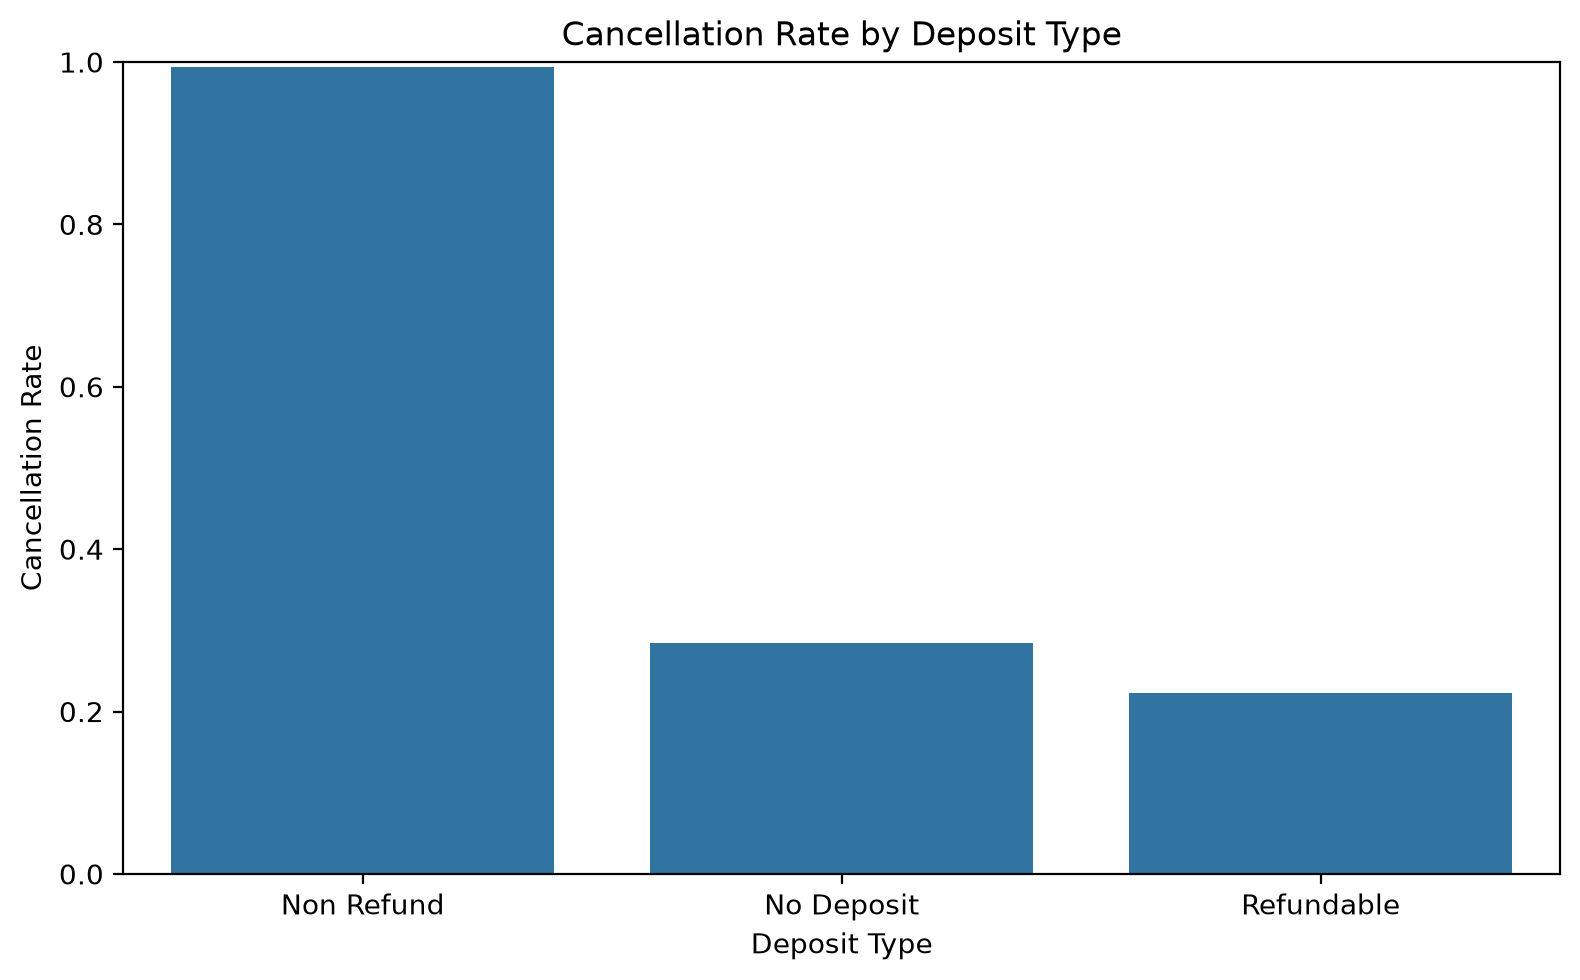

In [35]:
# Calculate cancellation rates by deposit type
deposit_summary = data.groupby("deposit_type")["is_canceled"].agg(
    Total_Bookings="count",
    Cancellations="sum",
    Cancellation_Rate="mean"
)

deposit_summary["Cancellation_Rate"] *= 100

display(deposit_summary.round(2))


# Visualize cancellation rates by deposit type
plt.figure(figsize=(8, 5))

sns.barplot(
    data=data,
    x="deposit_type",
    y="is_canceled",
    errorbar=None
)

plt.title("Cancellation Rate by Deposit Type")
plt.xlabel("Deposit Type")
plt.ylabel("Cancellation Rate")
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

Cancellation rates vary substantially across deposit types. Notably, 99.36% of Non Refund bookings were canceled, compared with 28.38% of No Deposit bookings. This counterintuitive result suggests that deposit type may be a highly informative predictor of cancellation behavior.

However, the observed relationship should not be interpreted as causal, as deposit policies may be associated with other booking characteristics. Additionally, the Refundable category contains only 162 observations, limiting the reliability of comparisons involving this group.

Further analysis is needed to investigate this unusually strong association and assess its importance in predictive modeling.